# Analyse multi-label RR / RH

Notebook exécutable de haut en bas, utilisant `clusterprep.metrics` et les artefacts effectivement enregistrés. Deux probabilités **sigmoid indépendantes** ; `[1,1]` est une cible valide.

**Par défaut : démonstration synthétique explicitement simulée, sans entraînement et sans FITS.** Pour vos expériences, renseigner `RUN_DIRS` ou `RESULTS_ROOT`. Aucun fichier existant n'est écrasé : chaque exécution crée un dossier d'export unique.

Les candidats suivent la politique sauvegardée. Une annotation absente n'est pas une preuve astrophysique d'absence : la convention négative historique est signalée, jamais corrigée implicitement. Les masques sauvegardés sont appliqués à tous les scores et aux seuils.

In [68]:
from pathlib import Path
import os, sys, json, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

# Paramètres modifiables. Aucun chemin personnel n'est requis.
RUN_DIR_ROOT = Path("/Users/antoinegdrn/PH_Project_I/results/transfer/fusion_multimodal_RR_RH_Transfer")
RUN_DIRS = [p for p in RUN_DIR_ROOT.iterdir() if p.is_dir()]  # chemins relatifs ou absolus vers les répertoires de résultats 2e sous répertoire (ex. results/experiments/2023-01-01_12-00-00)
RESULTS_ROOT = None                 # ex. Path("../results/experiments")
USE_SYNTHETIC_IF_EMPTY = True
COHORT = "all"                     # all, paired, raw_only
THRESHOLDS = None                   # None : seuils sauvegardés ; sinon {"RR": 0.5, "RH": 0.6}
THRESHOLD_METHOD = os.environ.get("CLUSTERPREP_THRESHOLD_METHOD", "stored")  # stored, fixed, f1, recall_at_precision
MIN_PRECISION = 0.8
THRESHOLD_GRID = [i / 100 for i in range(5, 100, 5)]
SEED = 42
BOOTSTRAP_ITERATIONS = int(os.environ.get("CLUSTERPREP_BOOTSTRAP_ITERATIONS", "200"))
MIN_COMBINATION_SUPPORT = 5
EXPORT_ROOT = Path(os.environ.get("CLUSTERPREP_ANALYSIS_OUTPUT_ROOT", "analysis_exports"))
SORT_BY = "model"                  # colonne de tri du tableau de synthèse

# Dépôt local ou installation pip : lancement depuis le dépôt ou notebooks/.
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates = [parent / "src", parent / "clusterprep" / "src"]
    found = next((p for p in candidates if (p / "clusterprep").is_dir()), None)
    if found:
        sys.path.insert(0, str(found))
        break
from clusterprep import multilabel_analysis as analysis
from clusterprep.metrics import resolve_thresholds
pd.set_option("display.max_columns", 30)
OUTPUT_DIR = analysis.create_output_directory(EXPORT_ROOT)
print("Exports :", OUTPUT_DIR.resolve())

def show_rows(rows, filename):
    frame = pd.DataFrame(rows)
    display(frame)
    analysis.export_rows(OUTPUT_DIR / filename, rows)
    return frame

def save_figure(fig, filename):
    destination = OUTPUT_DIR / filename
    if destination.exists():
        raise FileExistsError(destination)
    fig.savefig(destination, dpi=140, bbox_inches="tight")
    display(Image(filename=str(destination)))
    plt.close(fig)

Exports : /Users/antoinegdrn/PH_Project_I/clusterprep/notebooks/analysis_exports/analysis-20261012T082620-f07e118e


## 1. Chargement et contrôle des expériences

Fichiers requis : `config.json`, `metrics.json`, `splits.json`, `validation_predictions.csv`, `test_predictions.csv`. `history.jsonl` alimente les courbes lorsqu'il est présent. Les CSV doivent fournir les identifiants, les labels et probabilités RR/RH, ainsi que la disponibilité CHANDRA. Les masques sont lus dans `known_RR/RH` ; un ancien schéma n'est accepté que si sa politique permet de les reconstruire explicitement.

Unicité des clusters, identités du manifeste, séparation des splits, cohérence labels/masques et seuils sont contrôlées. Une expérience DE/NDE donnée explicitement est refusée ; la découverte par racine ne retient que RR/RH. Un fold absent des métadonnées reste inconnu.

In [69]:
if not RUN_DIRS:
    if RESULTS_ROOT is not None:
        RUN_DIRS = analysis.discover_runs(RESULTS_ROOT)
    elif USE_SYNTHETIC_IF_EMPTY:
        demo_parent = Path(tempfile.mkdtemp(prefix="clusterprep-analysis-"))
        RUN_DIRS = analysis.create_demo_runs(demo_parent / "synthetic_runs", seed=SEED)
        print("DÉMONSTRATION SYNTHÉTIQUE — probabilités simulées, aucune performance réelle.")
    else:
        raise ValueError("Renseigner RUN_DIRS ou RESULTS_ROOT, ou activer la démonstration synthétique.")
runs = [analysis.load_run(path) for path in RUN_DIRS]
if len({run.id for run in runs}) != len(runs):
    raise ValueError("Noms de runs dupliqués : utiliser une sélection aux identifiants uniques.")
summary = pd.DataFrame([run.summary() for run in runs]).sort_values(SORT_BY, na_position="last")
display(summary)
analysis.export_rows(OUTPUT_DIR / "experiments.csv", [run.summary() for run in sorted(runs, key=lambda r: str(r.summary().get(SORT_BY)))])
for run in runs:
    display(Markdown(f"**{run.id}**"))
    for issue in run.issues:
        print("•", issue)
groups = analysis.comparison_groups(runs, COHORT)
print(f"{len(groups)} groupe(s) de cohortes comparables. Des tests différents seront présentés séparément.")

,run_id,path,model,mode,seed,candidate_policy,best_epoch,seconds,fold_index,n_folds,J,L,max_order,threshold_method,threshold_RR,threshold_RH,n_train,n_validation,n_test
0,fusion_multimodal_RR_RH_Transfer-20261011T2055...,/Users/antoinegdrn/PH_Project_I/results/transf...,fusion,multimodal,42,positive,15,176.590016,None,None,None,None,None,f1,0.5,0.3,140,48,48


**fusion_multimodal_RR_RH_Transfer-20261011T205536-98ae8af4**

• Convention enregistrée/historique : annotation absente = négative ; cela ne prouve pas un négatif astrophysique fiable. Aucun label n'est réinterprété ici.
1 groupe(s) de cohortes comparables. Des tests différents seront présentés séparément.


## 2. Déséquilibre et qualité des annotations

Le comptage utilise **une observation par cluster**, jamais les 24 augmentations. Les cibles de validation/test viennent des CSV ; le train est reconstruit depuis les annotations du manifeste, sans accès aux images. Les colonnes confirmed/candidate restent indéfinies si le détail des annotations n'a pas été sauvegardé.

`unknown` désigne une combinaison partiellement ou totalement masquée ; elle n'est pas assimilée à `00`. Avec la population RR/RH actuelle, l'absence de `00` peut résulter de la règle d'éligibilité : aucune catégorie négative supplémentaire n'est inventée.

`has_chandra` indique un fichier CHANDRA associé, pas la fraction de pixels couverts. Cette fraction n’est pas exportée par les anciens runs ; elle ne peut donc pas être reconstituée ici.

In [70]:
annotation_details = [row for run in runs for row in analysis.annotation_rows(run)]
annotation_table = show_rows([row for run in runs for row in analysis.annotation_summary(run)], "annotation_supports.csv")
analysis.export_rows(OUTPUT_DIR / "annotations_by_cluster.csv", annotation_details)
detail_frame = pd.DataFrame(annotation_details)
combinations = detail_frame.groupby(["run_id", "split", "combination"]).size().rename("n_clusters").reset_index()
display(combinations)
analysis.export_rows(OUTPUT_DIR / "annotation_combinations.csv", combinations.to_dict("records"))
if not detail_frame.annotation_detail_available.all():
    print("Limite : distinction confirmé/candidat indisponible pour certains clusters.")
else:
    display(detail_frame.groupby(["run_id", "split"])[["confirmed_RR", "candidate_RR", "confirmed_RH", "candidate_RH"]].sum())
print("Les effectifs positifs/négatifs faibles rendent AP, AUC et les intervalles instables.")

,run_id,split,label,n_clusters,n_known,n_positive,n_negative,prevalence,n_chandra,annotation_detail_available
0,fusion_multimodal_RR_RH_Transfer-20261011T2055...,train,RR,140,140,13,127,0.092857,55,True
1,fusion_multimodal_RR_RH_Transfer-20261011T2055...,train,RH,140,140,52,88,0.371429,55,True
2,fusion_multimodal_RR_RH_Transfer-20261011T2055...,validation,RR,48,48,7,41,0.145833,14,True
3,fusion_multimodal_RR_RH_Transfer-20261011T2055...,validation,RH,48,48,15,33,0.312500,14,True
4,fusion_multimodal_RR_RH_Transfer-20261011T2055...,test,RR,48,48,6,42,0.125000,16,True
5,fusion_multimodal_RR_RH_Transfer-20261011T2055...,test,RH,48,48,16,32,0.333333,16,True


,run_id,split,combination,n_clusters
0,fusion_multimodal_RR_RH_Transfer-20261011T2055...,test,00,28
1,fusion_multimodal_RR_RH_Transfer-20261011T2055...,test,01,14
2,fusion_multimodal_RR_RH_Transfer-20261011T2055...,test,10,4
3,fusion_multimodal_RR_RH_Transfer-20261011T2055...,test,11,2
4,fusion_multimodal_RR_RH_Transfer-20261011T2055...,train,00,83
5,fusion_multimodal_RR_RH_Transfer-20261011T2055...,train,01,44
6,fusion_multimodal_RR_RH_Transfer-20261011T2055...,train,10,5
7,fusion_multimodal_RR_RH_Transfer-20261011T2055...,train,11,8
8,fusion_multimodal_RR_RH_Transfer-20261011T2055...,validation,00,29
9,fusion_multimodal_RR_RH_Transfer-20261011T2055...,validation,01,12


confirmed_RR  \
run_id                                             split                      
fusion_multimodal_RR_RH_Transfer-20261011T20553... test                   3   
                                                   train                 10   
                                                   validation             7   

                                                               candidate_RR  \
run_id                                             split                      
fusion_multimodal_RR_RH_Transfer-20261011T20553... test                   3   
                                                   train                  3   
                                                   validation             0   

                                                               confirmed_RH  \
run_id                                             split                      
fusion_multimodal_RR_RH_Transfer-20261011T20553... test                  12   
                                                   train                 38   
                                                   validation             9   

                                                               candidate_RH  
run_id                                             split                     
fusion_multimodal_RR_RH_Transfer-20261011T20553... test                   4  
                                                   train                 14  
                                                   validation             6

Les effectifs positifs/négatifs faibles rendent AP, AUC et les intervalles instables.


## 3. Seuils figés et performances

Les seuils sont fixés **avant** le calcul des scores test ci-dessous. `stored` réutilise la provenance sauvegardée ; `fixed` applique les seuils configurés ; `f1` ou `recall_at_precision` ne lisent que la validation. La grille est déterministe ; les ex æquo favorisent le seuil le plus proche de 0,5 puis le plus élevé. Sans deux classes connues ou contrainte réalisable, le seuil initial est conservé et la raison est affichée.

Le test sert à l'estimation finale, pas à choisir une méthode ou à modifier les seuils après inspection. Les scores de validation après optimisation sont optimistes. Les historiques gardent les seuils utilisés pendant l'entraînement.

AP et ROC-AUC utilisent les scores continus et exigent ici des positifs **et** des négatifs connus ; sinon `None`. Les macro-moyennes ignorent les labels non évaluables et publient leur nombre. Hamming divise par le nombre de **cellules connues** ; subset accuracy divise par le nombre de **clusters dont les deux labels sont connus**.

In [71]:
FROZEN_THRESHOLDS, SELECTIONS = {}, {}
for run in runs:
    initial = resolve_thresholds(THRESHOLDS) if THRESHOLDS is not None else run.thresholds
    if THRESHOLD_METHOD == "stored":
        if THRESHOLDS is not None:
            raise ValueError("Utiliser THRESHOLD_METHOD='fixed' pour remplacer les seuils sauvegardés.")
        selection = {"method": "stored", "thresholds": initial,
                     "saved_provenance": run.metrics.get("threshold_selection", run.metadata.get("evaluation", {"method": "fixed_legacy"}))}
    elif THRESHOLD_METHOD in {"fixed", "f1", "recall_at_precision"}:
        selection = analysis.validation_selection(run, method=THRESHOLD_METHOD, grid=THRESHOLD_GRID,
            min_precision=MIN_PRECISION, thresholds=initial, cohort="all")
    else:
        raise ValueError("THRESHOLD_METHOD inconnu")
    FROZEN_THRESHOLDS[run.id] = dict(selection["thresholds"])
    SELECTIONS[run.id] = selection
with (OUTPUT_DIR / "thresholds.json").open("x") as stream:
    json.dump(SELECTIONS, stream, indent=2, allow_nan=False)
display(SELECTIONS)
# Une seule décision de seuils ; toutes les sections suivantes réutilisent ces valeurs.
TEST_SCORES = {run.id: run.predictions["test"].cohort(COHORT).scores(FROZEN_THRESHOLDS[run.id]) for run in runs}
per_label_rows, global_rows = [], []
for run in runs:
    scores = TEST_SCORES[run.id]
    per_label_rows.extend({"run_id": run.id, "label": label, **{k: v for k, v in values.items() if not isinstance(v, (dict, list))}}
                          for label, values in scores["per_label"].items())
    global_rows.append({"run_id": run.id, "model": run.config.get("model"), "mode": run.config.get("mode"),
                       **analysis.flatten_metrics(scores)})
    if scores["roc_auc_macro_n_labels"] < 2 or scores["average_precision_macro_n_labels"] < 2:
        print(run.id, ": AUC/AP non définie pour au moins un label ; inspecter les supports.")
show_rows(per_label_rows, "test_per_label.csv")
show_rows(global_rows, "test_global.csv")
with (OUTPUT_DIR / "test_metrics.json").open("x") as stream:
    json.dump(TEST_SCORES, stream, indent=2, allow_nan=False)

{'fusion_multimodal_RR_RH_Transfer-20261011T205536-98ae8af4': {'method': 'stored',
  'thresholds': {'RR': 0.5, 'RH': 0.3},
  'saved_provenance': {'method': 'f1',
   'selection_split': 'validation',
   'thresholds': {'RR': 0.5, 'RH': 0.3},
   'grid': [0.05,
    0.1,
    0.15,
    0.2,
    0.25,
    0.3,
    0.35,
    0.4,
    0.45,
    0.5,
    0.55,
    0.6,
    0.65,
    0.7,
    0.75,
    0.8,
    0.85,
    0.9,
    0.95],
   'min_precision': None,
   'tie_break': 'closest_to_0.5_then_largest',
   'per_label': {'RR': {'n_known': 48,
     'n_positive': 7,
     'n_negative': 41,
     'status': 'selected',
     'threshold': 0.5},
    'RH': {'n_known': 48,
     'n_positive': 15,
     'n_negative': 33,
     'status': 'selected',
     'threshold': 0.3}}}}}

,run_id,label,precision,recall,f1,roc_auc,average_precision,balanced_accuracy,brier,threshold,support,n_positive,n_negative,n_known,prevalence,tn,fp,fn,tp
0,fusion_multimodal_RR_RH_Transfer-20261011T2055...,RR,0.187500,0.5000,0.272727,0.480159,0.156065,0.595238,0.214772,0.5,6,6,42,48,0.125000,29,13,3,3
1,fusion_multimodal_RR_RH_Transfer-20261011T2055...,RH,0.481481,0.8125,0.604651,0.695312,0.530544,0.687500,0.208574,0.3,16,16,32,48,0.333333,18,14,3,13


,run_id,model,mode,n_samples,n_fully_known,n_known,accuracy,subset_accuracy,hamming_accuracy,hamming_loss,micro_f1,weighted_f1,macro_f1,macro_f1_n_labels,roc_auc_macro,...,RH_f1,RH_roc_auc,RH_average_precision,RH_balanced_accuracy,RH_brier,RH_threshold,RH_support,RH_n_positive,RH_n_negative,RH_n_known,RH_prevalence,RH_tn,RH_fp,RH_fn,RH_tp
0,fusion_multimodal_RR_RH_Transfer-20261011T2055...,fusion,multimodal,48,48,96,0.4375,0.4375,0.65625,0.34375,0.492308,0.514126,0.438689,2,0.587736,...,0.604651,0.695312,0.530544,0.6875,0.208574,0.3,16,16,32,48,0.333333,18,14,3,13


## 4. Visualisations essentielles

La baseline PR est la prévalence parmi les annotations connues du label et de la cohorte affichée. Les matrices sont binaires et séparées ; aucune confusion multiclasses RR/RH n'est construite. Les histogrammes affichent des effectifs de clusters, pas des augmentations.

Les résultats par combinaison sont descriptifs et supprimés en dessous de `MIN_COMBINATION_SUPPORT`. Les courbes d'historique absentes ne sont ni interpolées ni inventées.

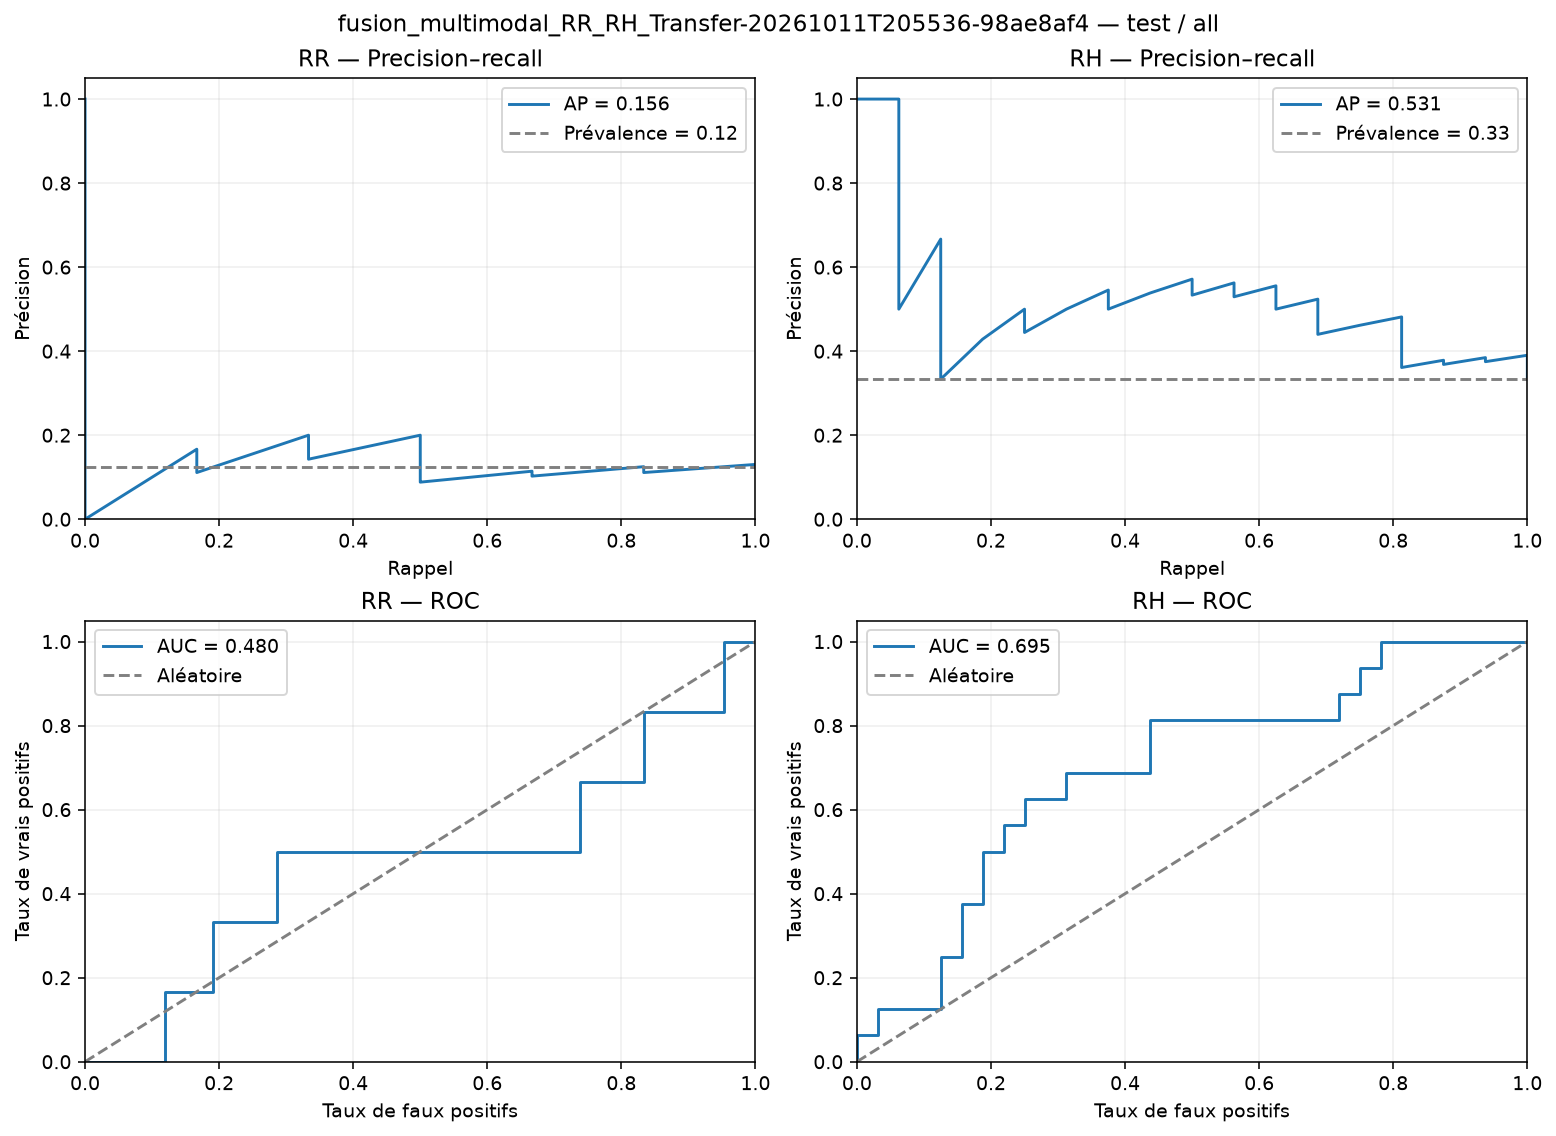

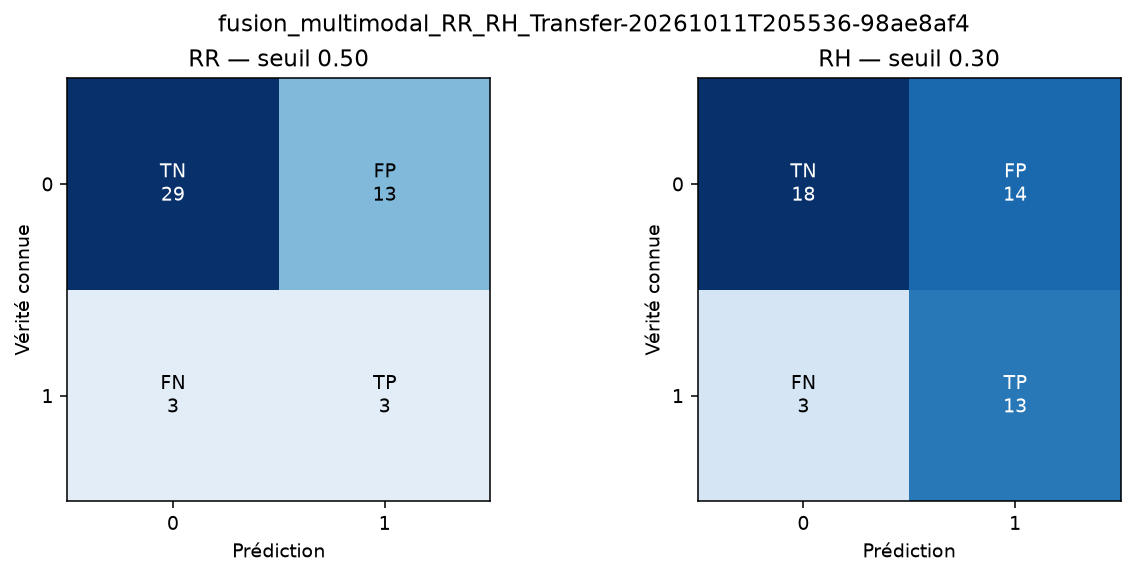

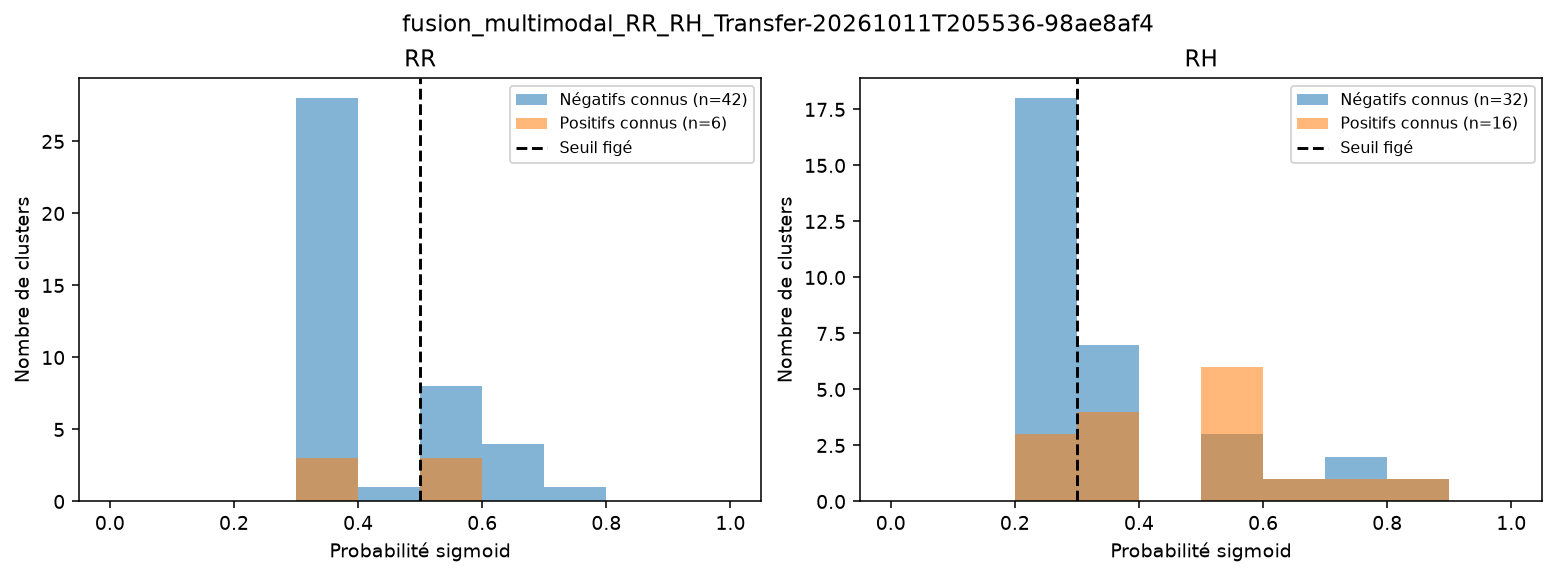

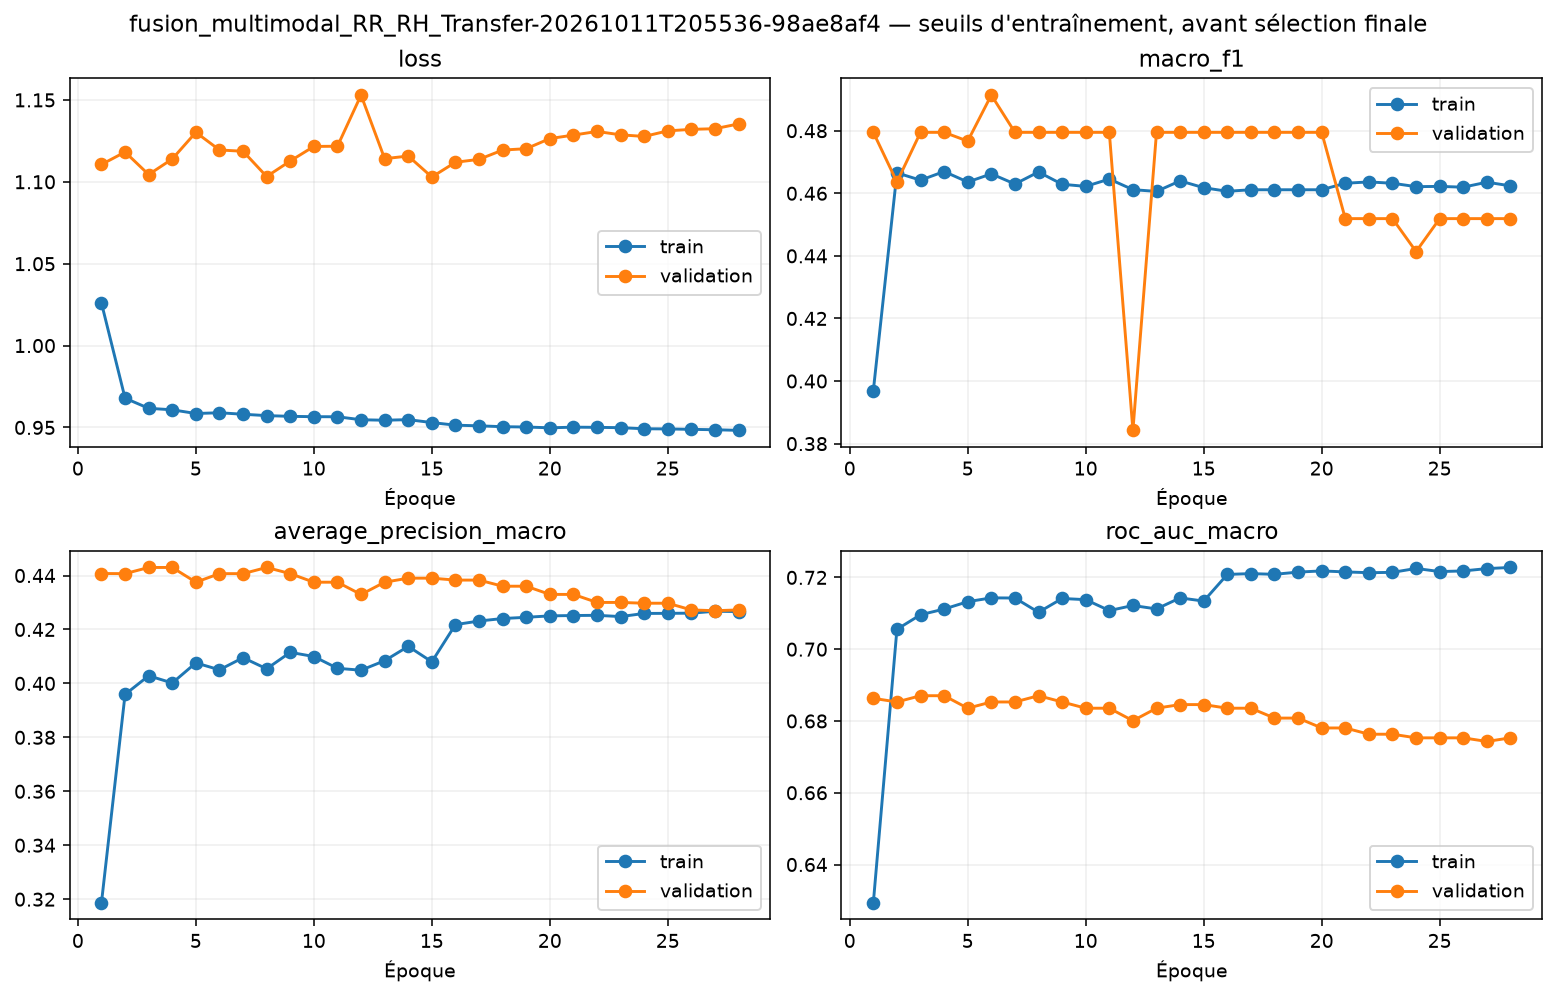

,combination,n_clusters,small_support,subset_accuracy
0,00,28,False,0.571429
1,10,4,True,NaN
2,01,14,False,0.285714
3,11,2,True,NaN
4,unknown,0,None,NaN


In [72]:
for run in runs:
    predictions = run.predictions["test"].cohort(COHORT)
    selected = FROZEN_THRESHOLDS[run.id]
    prefix = run.id
    save_figure(analysis.plot_score_curves(predictions, f"{run.id} — test / {COHORT}"), f"{prefix}-pr-roc.png")
    save_figure(analysis.plot_confusions(predictions, selected, run.id), f"{prefix}-confusion.png")
    save_figure(analysis.plot_probabilities(predictions, selected, run.id), f"{prefix}-probabilities.png")
    save_figure(analysis.plot_learning_history(run), f"{prefix}-history.png")
    show_rows(analysis.combination_scores(predictions, selected, MIN_COMBINATION_SUPPORT), f"{prefix}-combinations.csv")

## 5. Validation, seuils et erreurs à examiner

Ces courbes de seuil utilisent **uniquement la validation**, même lorsque la cohorte test est filtrée. Elles ne modifient pas les seuils déjà figés. Les tables FP/FN excluent les annotations masquées et sont exportées pour revue astrophysique.

Les sous-populations `paired` et `raw_only` réutilisent les mêmes seuils : aucune optimisation par sous-groupe sur le test. Des différences sur de faibles supports ne prouvent pas un gain lié à CHANDRA.

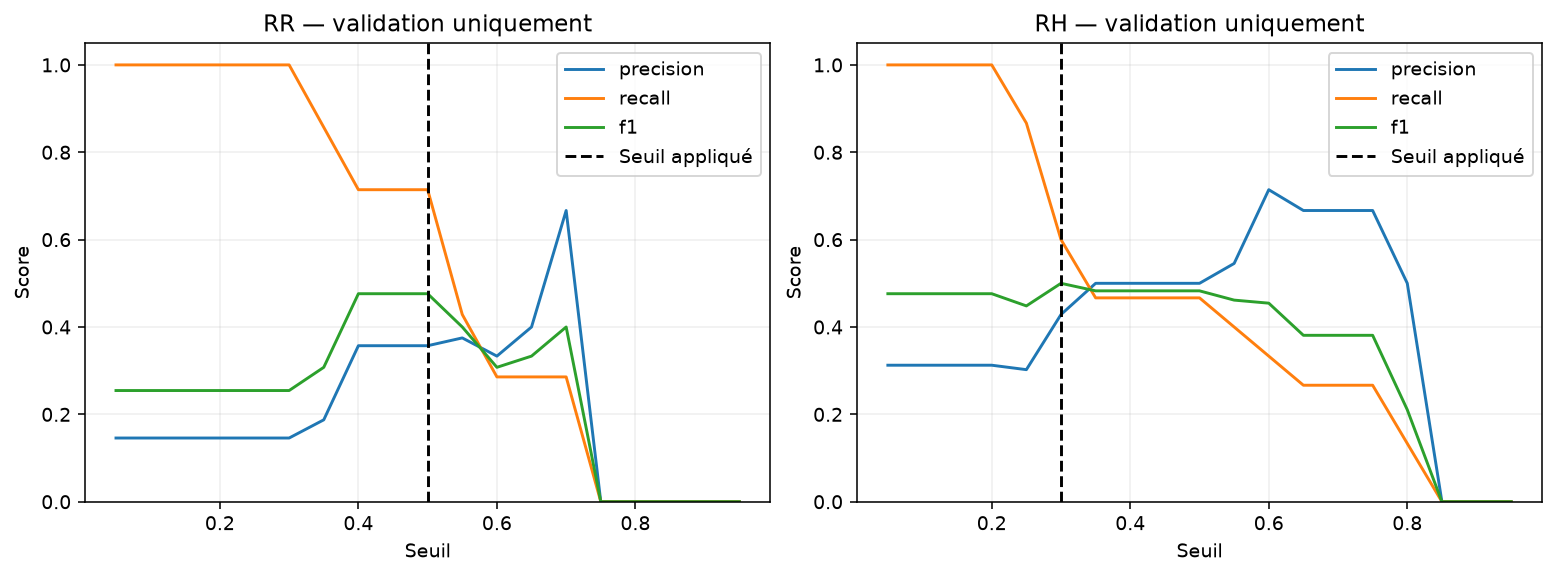

,cluster_id,key,label,error,has_chandra,probability_RR,label_RR,known_RR,probability_RH,label_RH,known_RH
0,PSZ2G031.93+78.71,PSZ2G031.93+78.71.fits,RR,FP,True,0.564484,0,True,0.589640,1,True
1,PSZ2G057.61+34.93,PSZ2G057.61+34.93.fits,RH,FP,True,0.571661,1,True,0.601978,0,True
2,PSZ2G058.31+41.96,PSZ2G058.31+41.96.fits,RH,FP,False,0.397001,0,True,0.350577,0,True
3,PSZ2G066.68+68.44,PSZ2G066.68+68.44.fits,RR,FP,True,0.629282,0,True,0.730161,0,True
4,PSZ2G066.68+68.44,PSZ2G066.68+68.44.fits,RH,FP,True,0.629282,0,True,0.730161,0,True
5,PSZ2G086.93+53.18,PSZ2G086.93+53.18.fits,RR,FP,True,0.550924,0,True,0.562822,1,True
6,PSZ2G094.44+36.13,PSZ2G094.44+36.13.fits,RR,FP,True,0.636936,0,True,0.735270,0,True
7,PSZ2G094.44+36.13,PSZ2G094.44+36.13.fits,RH,FP,True,0.636936,0,True,0.735270,0,True
8,PSZ2G097.78+46.95,PSZ2G097.78+46.95.fits,RH,FP,False,0.378843,0,True,0.320719,0,True
9,PSZ2G118.49+48.17,PSZ2G118.49+48.17.fits,RH,FP,False,0.379529,0,True,0.321473,0,True


,run_id,cohort,n_samples,n_fully_known,n_known,accuracy,subset_accuracy,hamming_accuracy,hamming_loss,micro_f1,weighted_f1,macro_f1,macro_f1_n_labels,roc_auc_macro,roc_auc_macro_n_labels,...,RH_f1,RH_roc_auc,RH_average_precision,RH_balanced_accuracy,RH_brier,RH_threshold,RH_support,RH_n_positive,RH_n_negative,RH_n_known,RH_prevalence,RH_tn,RH_fp,RH_fn,RH_tp
0,fusion_multimodal_RR_RH_Transfer-20261011T2055...,all,48,48,96,0.4375,0.4375,0.656250,0.343750,0.492308,0.514126,0.438689,2,0.587736,2,...,0.604651,0.695312,0.530544,0.687500,0.208574,0.3,16,16,32,48,0.333333,18,14,3,13
1,fusion_multimodal_RR_RH_Transfer-20261011T2055...,paired,16,16,32,0.0625,0.0625,0.375000,0.625000,0.545455,0.618947,0.517895,2,0.377900,2,...,0.720000,0.396825,0.590343,0.500000,0.277763,0.3,9,9,7,16,0.562500,0,7,0,9
2,fusion_multimodal_RR_RH_Transfer-20261011T2055...,raw_only,32,32,64,0.6250,0.6250,0.796875,0.203125,0.380952,0.311111,0.222222,2,0.417800,2,...,0.444444,0.605714,0.334657,0.645714,0.173979,0.3,7,7,25,32,0.218750,18,7,3,4


,run_id,cohort,n_samples,n_fully_known,n_known,accuracy,subset_accuracy,hamming_accuracy,hamming_loss,micro_f1,weighted_f1,macro_f1,macro_f1_n_labels,roc_auc_macro,roc_auc_macro_n_labels,...,RH_f1,RH_roc_auc,RH_average_precision,RH_balanced_accuracy,RH_brier,RH_threshold,RH_support,RH_n_positive,RH_n_negative,RH_n_known,RH_prevalence,RH_tn,RH_fp,RH_fn,RH_tp
0,fusion_multimodal_RR_RH_Transfer-20261011T2055...,all,48,48,96,0.4375,0.4375,0.656250,0.343750,0.492308,0.514126,0.438689,2,0.587736,2,...,0.604651,0.695312,0.530544,0.687500,0.208574,0.3,16,16,32,48,0.333333,18,14,3,13
1,fusion_multimodal_RR_RH_Transfer-20261011T2055...,paired,16,16,32,0.0625,0.0625,0.375000,0.625000,0.545455,0.618947,0.517895,2,0.377900,2,...,0.720000,0.396825,0.590343,0.500000,0.277763,0.3,9,9,7,16,0.562500,0,7,0,9
2,fusion_multimodal_RR_RH_Transfer-20261011T2055...,raw_only,32,32,64,0.6250,0.6250,0.796875,0.203125,0.380952,0.311111,0.222222,2,0.417800,2,...,0.444444,0.605714,0.334657,0.645714,0.173979,0.3,7,7,25,32,0.218750,18,7,3,4


In [73]:
subpopulation_rows = []
for run in runs:
    selected = FROZEN_THRESHOLDS[run.id]
    save_figure(analysis.plot_validation_thresholds(run, selected), f"{run.id}-validation-thresholds.png")
    show_rows(analysis.error_rows(run.predictions["test"].cohort(COHORT), selected), f"{run.id}-errors.csv")
    for cohort in ("all", "paired", "raw_only"):
        predictions = run.predictions["test"].cohort(cohort)
        if not len(predictions.keys):
            print(run.id, cohort, ": cohorte vide")
            continue
        subpopulation_rows.append({"run_id": run.id, "cohort": cohort,
                                  **analysis.flatten_metrics(predictions.scores(selected))})
show_rows(subpopulation_rows, "subpopulations.csv")

## 6. Comparaison et incertitude

Comparaison directe autorisée uniquement à mêmes clusters test, vérités, masques et politique d'annotation. Les groupes différents sont séparés explicitement. La même seed de bootstrap aligne les tirages lorsque les clusters sont identiques.

Les intervalles percentile à 95 % rééchantillonnent les **clusters**, à seuils et modèles figés. Ils ne prennent pas en compte l'incertitude de sélection du modèle, des seuils ou du catalogue. Les réplications à classe unique ne contribuent pas aux AUC/AP : `n_valid` indique combien restent. Les petits supports rendent ces intervalles fragiles ; aucune significativité n'est inférée.

Les folds documentés sont résumés séparément par moyenne et écart-type, sans traiter leurs modèles (trains chevauchants) comme indépendants. Les anciens résultats sans provenance de fold ne sont pas regroupés par supposition.

,metric,estimate,lower,upper,n_valid,iterations,seed,n_clusters
0,subset_accuracy,0.437500,0.291667,0.583333,200,200,42,48
1,hamming_accuracy,0.656250,0.562500,0.750000,200,200,42,48
2,micro_f1,0.492308,0.333333,0.600278,200,200,42,48
3,macro_f1,0.438689,0.277293,0.552114,200,200,42,48
4,roc_auc_macro,0.587736,0.403810,0.744111,200,200,42,48
5,average_precision_macro,0.343304,0.232471,0.484163,200,200,42,48
6,balanced_accuracy,0.641369,0.491609,0.768283,200,200,42,48
7,RR_precision,0.187500,0.000000,0.354118,200,200,42,48
8,RR_recall,0.500000,0.000000,1.000000,200,200,42,48
9,RR_f1,0.272727,0.000000,0.480500,200,200,42,48


,run_id,model,mode,n_samples,n_fully_known,n_known,accuracy,subset_accuracy,hamming_accuracy,hamming_loss,micro_f1,weighted_f1,macro_f1,macro_f1_n_labels,roc_auc_macro,...,RH_balanced_accuracy,RH_brier,RH_threshold,RH_support,RH_n_positive,RH_n_negative,RH_n_known,RH_prevalence,RH_tn,RH_fp,RH_fn,RH_tp,seconds,best_epoch,cohort_signature
0,fusion_multimodal_RR_RH_Transfer-20261011T2055...,fusion,multimodal,48,48,96,0.4375,0.4375,0.65625,0.34375,0.492308,0.514126,0.438689,2,0.587736,...,0.6875,0.208574,0.3,16,16,32,48,0.333333,18,14,3,13,176.590016,15,37a50e699e06f96a240e72b6d9c422dbcf494b46be6a65...


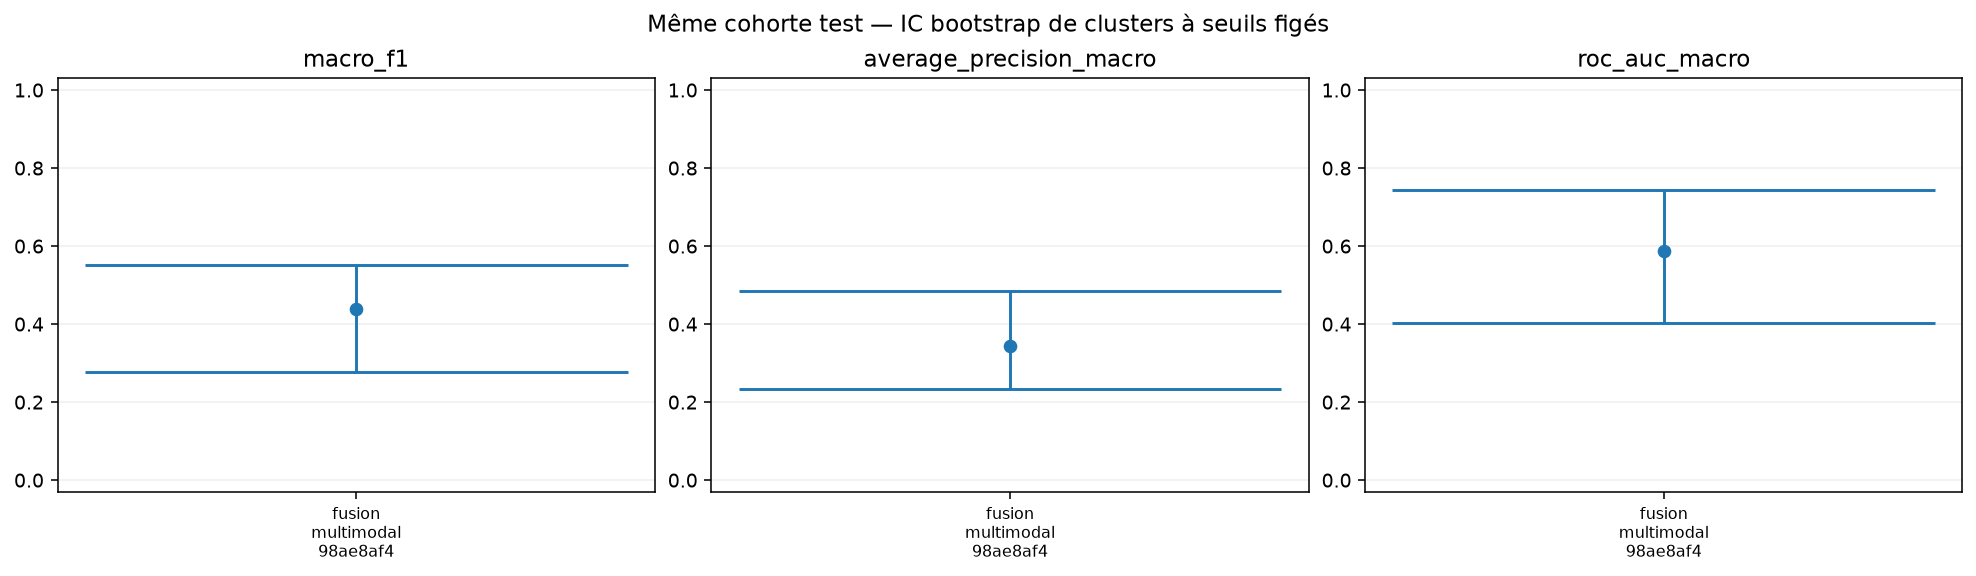

Pas de groupe de plusieurs folds documentés : aucun résumé inter-fold inventé.
Analyse terminée. Exports : /Users/antoinegdrn/PH_Project_I/clusterprep/notebooks/analysis_exports/analysis-20261012T082620-f07e118e


In [74]:
INTERVALS = {}
for run in runs:
    p = run.predictions["test"].cohort(COHORT)
    # Canonical order ensures paired bootstrap draws across compared models.
    p = p.subset(np.argsort(p.cluster_ids))
    INTERVALS[run.id] = analysis.bootstrap_clusters(p, FROZEN_THRESHOLDS[run.id], iterations=BOOTSTRAP_ITERATIONS, seed=SEED)
    show_rows(INTERVALS[run.id], f"{run.id}-bootstrap.csv")
for group_index, group in enumerate(groups.values(), 1):
    signature = analysis.assert_comparable(group, COHORT)
    ids = {run.id for run in group}
    rows = [{**row, "seconds": next(r for r in group if r.id == row["run_id"]).metrics.get("seconds"),
             "best_epoch": next(r for r in group if r.id == row["run_id"]).metrics.get("best_epoch"),
             "cohort_signature": signature}
            for row in global_rows if row["run_id"] in ids]
    show_rows(rows, f"comparison-group-{group_index}.csv")
    save_figure(analysis.plot_comparison(rows, INTERVALS), f"comparison-group-{group_index}.png")
folds = analysis.fold_summary(runs, COHORT, FROZEN_THRESHOLDS)
if folds:
    show_rows(folds, "fold_summary.csv")
else:
    print("Pas de groupe de plusieurs folds documentés : aucun résumé inter-fold inventé.")
manifest = {"runs": [str(run.path) for run in runs], "cohort": COHORT, "seed": SEED,
            "bootstrap_iterations": BOOTSTRAP_ITERATIONS, "threshold_method": THRESHOLD_METHOD,
            "thresholds": FROZEN_THRESHOLDS, "synthetic": any(run.metrics.get("synthetic", False) for run in runs)}
with (OUTPUT_DIR / "analysis_config.json").open("x") as stream:
    json.dump(manifest, stream, indent=2, allow_nan=False)
print("Analyse terminée. Exports :", OUTPUT_DIR.resolve())